In [1]:
import argparse
import sys
import numpy as np
import pandas as pd
import time

try:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    HAS_PLOTTING = True
except ImportError:
    HAS_PLOTTING = False

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn import metrics
from google.colab import drive
from sklearn.model_selection import GridSearchCV

drive.mount('/content/drive')
%cd '/content/drive/MyDrive/Optimización e inteligencia artificial /Proyecto Final'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/.shortcut-targets-by-id/1Y7Pn8kG_7La8zu5HNvTEPJEqItX3JkXO/Optimización e inteligencia artificial /Proyecto Final


In [2]:
CLASES = ["sano", "deriva", "fallo_duro"]
ROLLING_WINDOW = 5  # muestras (25 s a 5 s/muestra)
FEATURES = ["ltA_medido", "ltB_medido", "lt_residual", "residual_roll_mean", "residual_slope"]
UMBRAL_BASELINE = 0.15  # m — el mismo umbral de aviso ya implementado en el simulador (sin histéresis, por simplicidad)

In [3]:
def cargar_y_preparar(path_telemetria: str) -> pd.DataFrame:
    """Carga la telemetría y construye el target de 3 clases directamente desde
    las columnas de verdad de terreno que exporta el simulador (sensorA_fallo,
    sensorB_fallo, sensorA_deriva_activa, sensorB_deriva_activa) — no hace falta
    cruzar por tiempo contra el CSV de episodios para etiquetar."""
    tel = pd.read_csv(path_telemetria)
    requeridas = ["t", "ltA_medido", "ltB_medido", "lt_residual",
                  "sensorA_fallo", "sensorB_fallo", "sensorA_deriva_activa", "sensorB_deriva_activa"]
    faltantes = [c for c in requeridas if c not in tel.columns]
    if faltantes:
        raise ValueError(
            f"Faltan columnas {faltantes}. Este script requiere telemetría generada "
            f"con la versión del simulador que incluye las columnas de verdad de "
            f"terreno de sensores (posterior a la incorporación de sensorA_fallo, etc.)."
        )

    def clase(row):
        if row["sensorA_fallo"] or row["sensorB_fallo"]:
            return 2  # fallo_duro
        if row["sensorA_deriva_activa"] or row["sensorB_deriva_activa"]:
            return 1  # deriva
        return 0  # sano

    tel = tel.sort_values("t").reset_index(drop=True)
    tel["label"] = tel.apply(clase, axis=1)

    tel["residual_roll_mean"] = tel["lt_residual"].rolling(ROLLING_WINDOW, min_periods=1).mean()
    tel["residual_slope"] = tel["lt_residual"].diff(ROLLING_WINDOW).fillna(0) / ROLLING_WINDOW
    return tel

In [4]:
def dividir_train_test(tel: pd.DataFrame, path_episodios: str, n_episodios_prueba: int = 2):
    """Corte temporal, no aleatorio: entrena con la primera parte de la sesión y
    evalúa contra los últimos N episodios de falla (por defecto 2), que el modelo
    nunca ve durante el entrenamiento — evita fuga de datos entre muestras
    consecutivas y prueba generalización a severidades/tipos de falla nuevos."""
    ep = pd.read_csv(path_episodios).sort_values("inicio_t")
    if len(ep) < n_episodios_prueba + 1:
        raise ValueError(
            f"Solo hay {len(ep)} episodios en el CSV — se necesitan al menos "
            f"{n_episodios_prueba + 1} para dejar alguno en entrenamiento."
        )
    episodios_prueba = ep.iloc[-n_episodios_prueba:]
    corte_t = episodios_prueba["inicio_t"].min()

    print("Episodios reservados para prueba (nunca vistos en entrenamiento):")
    print(episodios_prueba[["causa", "inicio_t", "fin_t"]].to_string(index=False))
    print(f"\nCorte temporal: entrenamiento con t < {corte_t}, prueba con t >= {corte_t}")

    train = tel[tel["t"] < corte_t]
    test = tel[tel["t"] >= corte_t]
    return train, test

In [5]:
def entrenar_y_evaluar(train: pd.DataFrame, test: pd.DataFrame):
    Xtr, ytr = train[FEATURES], train["label"]
    Xte, yte = test[FEATURES], test["label"]

    print(f"\nEntrenamiento: {len(Xtr)} muestras — clases: {ytr.value_counts().sort_index().to_dict()}")
    print(f"Prueba:        {len(Xte)} muestras — clases: {yte.value_counts().sort_index().to_dict()}")


    param_grid = {'n_estimators': np.arange(10,110,10),
              'criterion': ['gini','entropy'],
              'max_depth': [2,3,5,10]
    }
    # Ajuste del GridSearchCV
    #RF_gridSearch = GridSearchCV(RandomForestClassifier(), param_grid)
    #RF_gridSearch.fit(Xtr, ytr)


    clf = GridSearchCV(RandomForestClassifier(), param_grid)
     #(n_estimators=[200], max_depth=5, class_weight="balanced", random_state=42)
    clf.fit(Xtr, ytr)
    pred = clf.best_estimator_.predict(Xte)
    print("Accuracy:", metrics.accuracy_score(y_test, y_pred))


    print("\n--- Reporte de clasificación (episodios nunca vistos en entrenamiento) ---")
    presentes = sorted(set(yte) | set(pred))
    print(classification_report(yte, pred, labels=presentes, zero_division=0,
                                 target_names=[CLASES[i] for i in presentes]))
    print("Matriz de confusión (filas = real, columnas = predicho; orden: sano, deriva, fallo_duro):")
    print(confusion_matrix(yte, pred, labels=[0, 1, 2]))

    recall_fallo_duro = None
    if (yte == 2).sum() > 0:
        recall_fallo_duro = ((pred == 2) & (yte == 2)).sum() / (yte == 2).sum()
        print(f"\n>>> Recall específico sobre 'fallo_duro': {recall_fallo_duro:.2f} <<<")
        if recall_fallo_duro < 0.5:
            print(">>> HALLAZGO ESPERADO: el modelo, basado en el residual, es prácticamente")
            print(">>> ciego al fallo duro — ver la explicación en el docstring de este script.")

    # Comparación binaria contra el umbral fijo que ya usa el simulador
    real_anomalia = (yte > 0).astype(int)
    baseline_pred = (test["lt_residual"] > UMBRAL_BASELINE).astype(int)
    modelo_pred_bin = (pred > 0).astype(int)
    recall_baseline = (baseline_pred[real_anomalia == 1] == 1).mean() if (real_anomalia == 1).any() else float("nan")
    recall_modelo = (modelo_pred_bin[real_anomalia == 1] == 1).mean() if (real_anomalia == 1).any() else float("nan")
    print(f"\nComparación binaria '¿hay alguna anomalía?' (deriva o fallo, sin distinguir tipo):")
    print(f"  Línea base (umbral fijo {UMBRAL_BASELINE} m, sin histéresis): recall = {recall_baseline:.2f}")
    print(f"  Modelo Random Forest:                                        recall = {recall_modelo:.2f}")

    return clf, test.assign(pred=pred)

In [6]:
parser = argparse.ArgumentParser(description="Modelo de detección de anomalías de sensor sobre datos del simulador COP-05.")
parser.add_argument("--telemetria", default="/content/drive/MyDrive/Optimización e inteligencia artificial /Proyecto Final/telemetria.csv", help="CSV de telemetría (default: /content/drive/MyDrive/Optimización e inteligencia artificial /Proyecto Final/telemetria.csv)")
parser.add_argument("--episodios", default="episodios.csv", help="CSV de episodios de falla (default: episodios.csv)")
parser.add_argument("--episodios-prueba", type=int, default=2, help="Nº de últimos episodios a reservar para prueba (default: 2)")
# Se pasa args=[] para evitar que falle con los argumentos por defecto del kernel de Jupyter/Colab
args = parser.parse_args(args=[])

print("=" * 70)
print("DETECCIÓN DE ANOMALÍAS DE SENSOR — Simulador COP-05, PTAR Bello")
print("=" * 70)
print("ADVERTENCIA: dataset sintético — ver docstring del script antes de interpretar resultados.\n")

tel = cargar_y_preparar(args.telemetria)
print(f"Telemetría cargada: {len(tel)} filas.")
print(f"Distribución de clases en toda la sesión: "
      f"{dict(zip(CLASES, tel['label'].value_counts().sort_index().tolist()))}")

DETECCIÓN DE ANOMALÍAS DE SENSOR — Simulador COP-05, PTAR Bello
ADVERTENCIA: dataset sintético — ver docstring del script antes de interpretar resultados.

Telemetría cargada: 518 filas.
Distribución de clases en toda la sesión: {'sano': 336, 'deriva': 170, 'fallo_duro': 12}


In [7]:
train, test = dividir_train_test(tel, args.episodios, args.episodios_prueba)

Episodios reservados para prueba (nunca vistos en entrenamiento):
                    causa  inicio_t  fin_t
Deriva gradual LT-051004A      1430   1930
  Fallo medida LT-051004A      2230   2290

Corte temporal: entrenamiento con t < 1430, prueba con t >= 1430


### **Optimización de hiperparametros usando búsqueda de grilla**

In [8]:
Xtr, ytr = train[FEATURES], train["label"]
Xte, yte = test[FEATURES], test["label"]

print(f"\nEntrenamiento: {len(Xtr)} muestras — clases: {ytr.value_counts().sort_index().to_dict()}")
print(f"Prueba:        {len(Xte)} muestras — clases: {yte.value_counts().sort_index().to_dict()}")


param_grid = {'n_estimators': np.arange(10,110,10),
          'criterion': ['gini','entropy'],
          'max_depth': [2,3,5,10]
}
# Ajuste del GridSearchCV
#RF_gridSearch = GridSearchCV(RandomForestClassifier(), param_grid)
#RF_gridSearch.fit(Xtr, ytr)

start_time = time.time()
clf = GridSearchCV(RandomForestClassifier(), param_grid)
  #(n_estimators=[200], max_depth=5, class_weight="balanced", random_state=42)
clf.fit(Xtr, ytr)
#Tiempo de entrenamiento
time_fit = time.time() - start_time
print(f"Tiempo de entrenamiento usando búsqueda de grilla: {time_fit:.2f} (s)")


Entrenamiento: 286 muestras — clases: {0: 216, 1: 70}
Prueba:        232 muestras — clases: {0: 120, 1: 100, 2: 12}
Tiempo de entrenamiento usando búsqueda de grilla: 57.68 (s)


In [9]:
pred = clf.best_estimator_.predict(Xte)
print("Accuracy:", metrics.accuracy_score(yte, pred))

Accuracy: 0.9310344827586207


In [10]:
#Podemos ver que parametros fueron los seleccionados
clf.best_params_

{'criterion': 'gini', 'max_depth': 2, 'n_estimators': np.int64(10)}

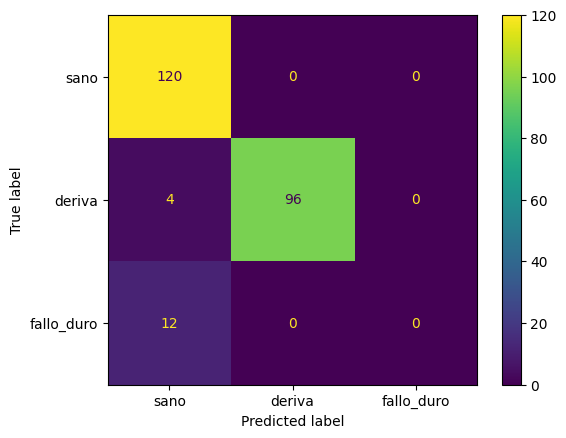

In [11]:
# Activar renderizado de gráficos en el notebook
%matplotlib inline
import matplotlib.pyplot as plt

# Otra alternativa para analizar el desempeño es la matriz de confusion
# también podemos calcularla desde la libreria sklearn especificando las 3 clases
cm_rf = confusion_matrix(yte, pred, labels=[0, 1, 2])
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=CLASES)

# Graficar y forzar visualización
disp.plot()
plt.show()

```
cm_rf = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=RF_gridSearch.best_estimator_.classes_)
disp.plot()
```

El error ocurre porque hay un desajuste de tamaños entre la matriz de confusión y las etiquetas que intentas mostrar:

Tu conjunto de entrenamiento (train) solo contenía datos de las clases 0 (sano) y 1 (deriva). Por lo tanto, el estimador clf solo aprendió esas 2 clases. Así, clf.best_estimator_.classes_ contiene [0, 1].
Sin embargo, tu conjunto de prueba (test) sí tiene muestras con la clase 2 (fallo_duro). Al calcular la matriz de confusión con confusion_matrix(yte, pred), se genera una matriz de 3x3 (porque yte tiene valores del 0 al 2).
Al intentar graficar una matriz de 3x3 usando solo 2 etiquetas ([0, 1]), Matplotlib falla con el error de discrepancia.
Para solucionarlo, podemos pasarle de forma explícita el parámetro labels=[0, 1, 2] a la función de la matriz de confusión y usar la lista completa de nuestras clases (CLASES) para mostrar correctamente la matriz de 3x3.

In [12]:
print("\n--- Reporte de clasificación (episodios nunca vistos en entrenamiento) ---")
presentes = sorted(set(yte) | set(pred))
print(classification_report(yte, pred, labels=presentes, zero_division=0,
                              target_names=[CLASES[i] for i in presentes]))
print("Matriz de confusión (filas = real, columnas = predicho; orden: sano, deriva, fallo_duro):")
print(confusion_matrix(yte, pred, labels=[0, 1, 2]))

recall_fallo_duro = None
if (yte == 2).sum() > 0:
    recall_fallo_duro = ((pred == 2) & (yte == 2)).sum() / (yte == 2).sum()
    print(f"\n>>> Recall específico sobre 'fallo_duro': {recall_fallo_duro:.2f} <<<")
    if recall_fallo_duro < 0.5:
        print(">>> HALLAZGO ESPERADO: el modelo, basado en el residual, es prácticamente")
        print(">>> ciego al fallo duro — ver la explicación en el docstring de este script.")

# Comparación binaria contra el umbral fijo que ya usa el simulador
real_anomalia = (yte > 0).astype(int)
baseline_pred = (test["lt_residual"] > UMBRAL_BASELINE).astype(int)
modelo_pred_bin = (pred > 0).astype(int)
recall_baseline = (baseline_pred[real_anomalia == 1] == 1).mean() if (real_anomalia == 1).any() else float("nan")
recall_modelo = (modelo_pred_bin[real_anomalia == 1] == 1).mean() if (real_anomalia == 1).any() else float("nan")
print(f"\nComparación binaria '¿hay alguna anomalía?' (deriva o fallo, sin distinguir tipo):")
print(f"  Línea base (umbral fijo {UMBRAL_BASELINE} m, sin histéresis): recall = {recall_baseline:.2f}")
print(f"  Modelo Random Forest:                                        recall = {recall_modelo:.2f}")


--- Reporte de clasificación (episodios nunca vistos en entrenamiento) ---
              precision    recall  f1-score   support

        sano       0.88      1.00      0.94       120
      deriva       1.00      0.96      0.98       100
  fallo_duro       0.00      0.00      0.00        12

    accuracy                           0.93       232
   macro avg       0.63      0.65      0.64       232
weighted avg       0.89      0.93      0.91       232

Matriz de confusión (filas = real, columnas = predicho; orden: sano, deriva, fallo_duro):
[[120   0   0]
 [  4  96   0]
 [ 12   0   0]]

>>> Recall específico sobre 'fallo_duro': 0.00 <<<
>>> HALLAZGO ESPERADO: el modelo, basado en el residual, es prácticamente
>>> ciego al fallo duro — ver la explicación en el docstring de este script.

Comparación binaria '¿hay alguna anomalía?' (deriva o fallo, sin distinguir tipo):
  Línea base (umbral fijo 0.15 m, sin histéresis): recall = 0.71
  Modelo Random Forest:                                

------------------------------------------
------------------------------------------
### **Optimización de hiperparametros usando búsqueda aleatoria**
------------------------------------------
------------------------------------------

In [13]:
#Ahora, vamos a seleccionar los hiperparametros empleando busqueda aleatoria
#este tipo de optimizador tambien se encuentra en sklearn
from sklearn.model_selection import RandomizedSearchCV
#Creamos la grilla de hiperparametros, entre las cuales se seleccionara de forma
#aleatoria la mejor configuracion
param_grid = {'n_estimators': np.arange(10,110,10),
              'criterion': ['gini','entropy'],
              'max_depth': [2,3,5,10]
}
#Definimos el clasificador base
base_estimator = RandomForestClassifier()
#Seleccionamos los hiperparametros
RF_randomSearch = RandomizedSearchCV(base_estimator, param_grid, n_iter=15)
#Nota: despues de emplear RandomizedSearchVC tambien se requiere entrenar
#el modelo
#Tiempo de inicio
start_time = time.time()
RF_randomSearch.fit(Xtr, ytr)
#Tiempo de entrenamiento
time_fit = time.time() - start_time
print(f"Tiempo de entrenamiento con búsqueda aleatoria: {time_fit:.2f} (s)")

Tiempo de entrenamiento con búsqueda aleatoria: 8.16 (s)


In [14]:
#Podemos ver que parametros fueron los seleccionados
RF_randomSearch.best_params_

{'n_estimators': np.int64(70), 'max_depth': 3, 'criterion': 'gini'}

In [15]:
#Usamos el clasificador y analizamos su precision
pred = RF_randomSearch.best_estimator_.predict(Xte)
print("Accuracy:", metrics.accuracy_score(yte, pred))

Accuracy: 0.9353448275862069


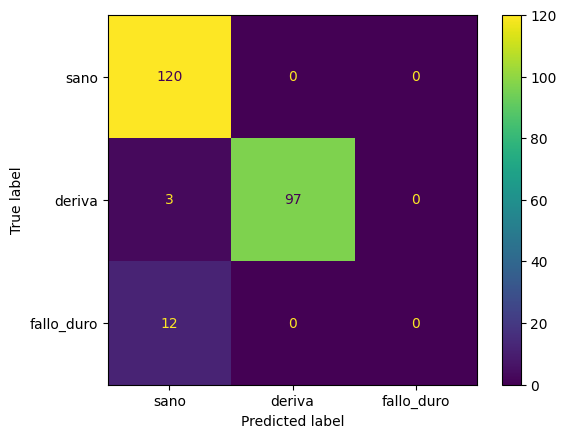

In [16]:
# Activar renderizado de gráficos en el notebook
%matplotlib inline
import matplotlib.pyplot as plt

# Otra alternativa para analizar el desempeño es la matriz de confusion
# también podemos calcularla desde la libreria sklearn especificando las 3 clases
cm_rf = confusion_matrix(yte, pred, labels=[0, 1, 2])
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=CLASES)

# Graficar y forzar visualización
disp.plot()
plt.show()

In [17]:
print("\n--- Reporte de clasificación (episodios nunca vistos en entrenamiento) ---")
presentes = sorted(set(yte) | set(pred))
print(classification_report(yte, pred, labels=presentes, zero_division=0,
                              target_names=[CLASES[i] for i in presentes]))
print("Matriz de confusión (filas = real, columnas = predicho; orden: sano, deriva, fallo_duro):")
print(confusion_matrix(yte, pred, labels=[0, 1, 2]))

recall_fallo_duro = None
if (yte == 2).sum() > 0:
    recall_fallo_duro = ((pred == 2) & (yte == 2)).sum() / (yte == 2).sum()
    print(f"\n>>> Recall específico sobre 'fallo_duro': {recall_fallo_duro:.2f} <<<")
    if recall_fallo_duro < 0.5:
        print(">>> HALLAZGO ESPERADO: el modelo, basado en el residual, es prácticamente")
        print(">>> ciego al fallo duro — ver la explicación en el docstring de este script.")

# Comparación binaria contra el umbral fijo que ya usa el simulador
real_anomalia = (yte > 0).astype(int)
baseline_pred = (test["lt_residual"] > UMBRAL_BASELINE).astype(int)
modelo_pred_bin = (pred > 0).astype(int)
recall_baseline = (baseline_pred[real_anomalia == 1] == 1).mean() if (real_anomalia == 1).any() else float("nan")
recall_modelo = (modelo_pred_bin[real_anomalia == 1] == 1).mean() if (real_anomalia == 1).any() else float("nan")
print(f"\nComparación binaria '¿hay alguna anomalía?' (deriva o fallo, sin distinguir tipo):")
print(f"  Línea base (umbral fijo {UMBRAL_BASELINE} m, sin histéresis): recall = {recall_baseline:.2f}")
print(f"  Modelo Random Forest:                                        recall = {recall_modelo:.2f}")


--- Reporte de clasificación (episodios nunca vistos en entrenamiento) ---
              precision    recall  f1-score   support

        sano       0.89      1.00      0.94       120
      deriva       1.00      0.97      0.98       100
  fallo_duro       0.00      0.00      0.00        12

    accuracy                           0.94       232
   macro avg       0.63      0.66      0.64       232
weighted avg       0.89      0.94      0.91       232

Matriz de confusión (filas = real, columnas = predicho; orden: sano, deriva, fallo_duro):
[[120   0   0]
 [  3  97   0]
 [ 12   0   0]]

>>> Recall específico sobre 'fallo_duro': 0.00 <<<
>>> HALLAZGO ESPERADO: el modelo, basado en el residual, es prácticamente
>>> ciego al fallo duro — ver la explicación en el docstring de este script.

Comparación binaria '¿hay alguna anomalía?' (deriva o fallo, sin distinguir tipo):
  Línea base (umbral fijo 0.15 m, sin histéresis): recall = 0.71
  Modelo Random Forest:                                

---------------------------------
---------------------------------
### **Optimización de hiperparametros usando optimización bayesiana**
---------------------------------
---------------------------------

In [18]:
#Instalar libreria
!pip install scikit-optimize

In [19]:
import numpy as np
from skopt import BayesSearchCV
#Creamos la grilla con los parametros a seleccionar
param_grid = {'n_estimators':   np.arange(10,100,10),
              'criterion': ['gini','entropy'],
              'max_depth': [3,5,10,20]
}
#Defimos el clasificador base
base_estimator = RandomForestClassifier()
#Realizamos la busqueda de los hiperparametros

#Ahora, vamos a seleccionar los hiperparametros empleando busqueda aleatoria
#este tipo de optimizador tambien se encuentra en sklearn
#Tiempo de inicio
start_time = time.time()
RF_optBay = BayesSearchCV(base_estimator,param_grid,n_iter=15)
#Nota: no se olviden de invocar el metodo para entrenar .fit
RF_optBay.fit(Xtr,ytr)
#Tiempo de entrenamiento
time_fit = time.time() - start_time
print(f"Tiempo de entrenamiento Optimización Bayesiana: {time_fit:.2f} (s)")

Tiempo de entrenamiento Optimización Bayesiana: 35.17 (s)


In [20]:
#Calculamos la precision
y_pred=RF_optBay.predict(Xte)
print("Accuracy - Opt", metrics.accuracy_score(yte,y_pred))

Accuracy - Opt 0.9310344827586207


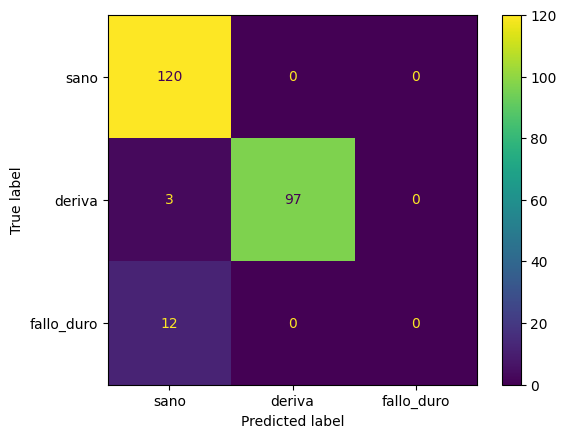

In [21]:
# Activar renderizado de gráficos en el notebook
%matplotlib inline
import matplotlib.pyplot as plt

# Otra alternativa para analizar el desempeño es la matriz de confusion
# también podemos calcularla desde la libreria sklearn especificando las 3 clases
cm_rf = confusion_matrix(yte, pred, labels=[0, 1, 2])
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=CLASES)

# Graficar y forzar visualización
disp.plot()
plt.show()

In [22]:
print("\n--- Reporte de clasificación (episodios nunca vistos en entrenamiento) ---")
presentes = sorted(set(yte) | set(pred))
print(classification_report(yte, pred, labels=presentes, zero_division=0,
                              target_names=[CLASES[i] for i in presentes]))
print("Matriz de confusión (filas = real, columnas = predicho; orden: sano, deriva, fallo_duro):")
print(confusion_matrix(yte, pred, labels=[0, 1, 2]))

recall_fallo_duro = None
if (yte == 2).sum() > 0:
    recall_fallo_duro = ((pred == 2) & (yte == 2)).sum() / (yte == 2).sum()
    print(f"\n>>> Recall específico sobre 'fallo_duro': {recall_fallo_duro:.2f} <<<")
    if recall_fallo_duro < 0.5:
        print(">>> HALLAZGO ESPERADO: el modelo, basado en el residual, es prácticamente")
        print(">>> ciego al fallo duro — ver la explicación en el docstring de este script.")

# Comparación binaria contra el umbral fijo que ya usa el simulador
real_anomalia = (yte > 0).astype(int)
baseline_pred = (test["lt_residual"] > UMBRAL_BASELINE).astype(int)
modelo_pred_bin = (pred > 0).astype(int)
recall_baseline = (baseline_pred[real_anomalia == 1] == 1).mean() if (real_anomalia == 1).any() else float("nan")
recall_modelo = (modelo_pred_bin[real_anomalia == 1] == 1).mean() if (real_anomalia == 1).any() else float("nan")
print(f"\nComparación binaria '¿hay alguna anomalía?' (deriva o fallo, sin distinguir tipo):")
print(f"  Línea base (umbral fijo {UMBRAL_BASELINE} m, sin histéresis): recall = {recall_baseline:.2f}")
print(f"  Modelo Random Forest:                                        recall = {recall_modelo:.2f}")


--- Reporte de clasificación (episodios nunca vistos en entrenamiento) ---
              precision    recall  f1-score   support

        sano       0.89      1.00      0.94       120
      deriva       1.00      0.97      0.98       100
  fallo_duro       0.00      0.00      0.00        12

    accuracy                           0.94       232
   macro avg       0.63      0.66      0.64       232
weighted avg       0.89      0.94      0.91       232

Matriz de confusión (filas = real, columnas = predicho; orden: sano, deriva, fallo_duro):
[[120   0   0]
 [  3  97   0]
 [ 12   0   0]]

>>> Recall específico sobre 'fallo_duro': 0.00 <<<
>>> HALLAZGO ESPERADO: el modelo, basado en el residual, es prácticamente
>>> ciego al fallo duro — ver la explicación en el docstring de este script.

Comparación binaria '¿hay alguna anomalía?' (deriva o fallo, sin distinguir tipo):
  Línea base (umbral fijo 0.15 m, sin histéresis): recall = 0.71
  Modelo Random Forest:                                